### Aula 05: Análise de Agrupamento (`Clustering`) em Dados de Crédito

Este notebook tem como objetivo identificar grupos de clientes com perfis semelhantes nos dados de concessão de crédito. Para isso, utilizaremos duas técnicas de agrupamento não supervisionado: K-Means e Clusterização Hierárquica.

#### 1\. Instalação e Importação de Bibliotecas

Primeiro, garanta que todas as bibliotecas necessárias estejam instaladas. A biblioteca `scikit-learn` é o principal framework para os algoritmos de machine learning.

```bash
pip install pandas scikit-learn matplotlib scipy
```

In [21]:
!pip install pandas scikit-learn matplotlib scipy

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


-----

#### 2\. Carregamento e Pré-processamento dos Dados

Os algoritmos de agrupamento baseados em distância (como K-Means e Hierárquico) exigem que os dados sejam numéricos. Como o nosso arquivo `credito.csv` possui variáveis categóricas (`Emprego`, `Estado`, `Crédito`), precisaremos convertê-las utilizando a técnica de **One-Hot Encoding**.

Além disso, para garantir que as variáveis numéricas (`Idade`, `Renda`) não dominem o cálculo de distância, padronizaremos suas escalas usando `StandardScaler`.

In [2]:
# Carregando o DataFrame do arquivo CSV
df = pd.read_csv('datasets/credito.csv')

print("Dados originais:")
print(df.head())

# Identificando colunas categóricas e numéricas
colunas_categoricas = ['emprego', 'estado', 'credito']
colunas_numericas = ['idade', 'renda']

# Aplicando One-Hot Encoding nas colunas categóricas
df_encoded = pd.get_dummies(df, columns=colunas_categoricas)

# Padronizando as colunas numéricas
scaler = StandardScaler()
df_encoded[colunas_numericas] = scaler.fit_transform(df_encoded[colunas_numericas])

print("\nDados pré-processados (One-Hot Encoded e Padronizados):")
df_encoded.head()

Dados originais:
  emprego      estado  idade  renda credito
0     Sim    Solteiro     25   9500     Sim
1     Não      Casado     37   8000     Não
2     Não    Solteiro     22   7000     Não
3     Sim      Casado     44  12000     Sim
4     Não  Divorciado     51   9000     Sim

Dados pré-processados (One-Hot Encoded e Padronizados):


,idade,renda,emprego_Não,emprego_Sim,estado_Casado,estado_Divorciado,estado_Solteiro,credito_Não,credito_Sim
0,-1.145697,0.178243,False,True,False,False,True,False,True
1,-0.265520,-0.248457,True,False,True,False,False,True,False
2,-1.365741,-0.532924,True,False,False,False,True,True,False
3,0.247917,0.889411,False,True,True,False,False,False,True
4,0.761353,0.036010,True,False,False,True,False,False,True


-----

#### 3\. Agrupamento com K-Means

O K-Means é um algoritmo que particiona os dados em um número pré-definido de clusters (`k`). Ele funciona de forma iterativa, atribuindo cada ponto ao seu centroide mais próximo e depois recalculando a posição dos centroides. Vamos escolher **3 clusters** para este exemplo.

In [3]:
# Definindo o número de clusters (k)
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

# Treinando o modelo
kmeans.fit(df_encoded)

# Adicionando a coluna de cluster ao DataFrame original
df['Cluster_KMeans'] = kmeans.labels_

print("\nResultados do Agrupamento K-Means:")
df.head()


Resultados do Agrupamento K-Means:


,emprego,estado,idade,renda,credito,Cluster_KMeans
0,Sim,Solteiro,25,9500,Sim,1
1,Não,Casado,37,8000,Não,2
2,Não,Solteiro,22,7000,Não,1
3,Sim,Casado,44,12000,Sim,0
4,Não,Divorciado,51,9000,Sim,0


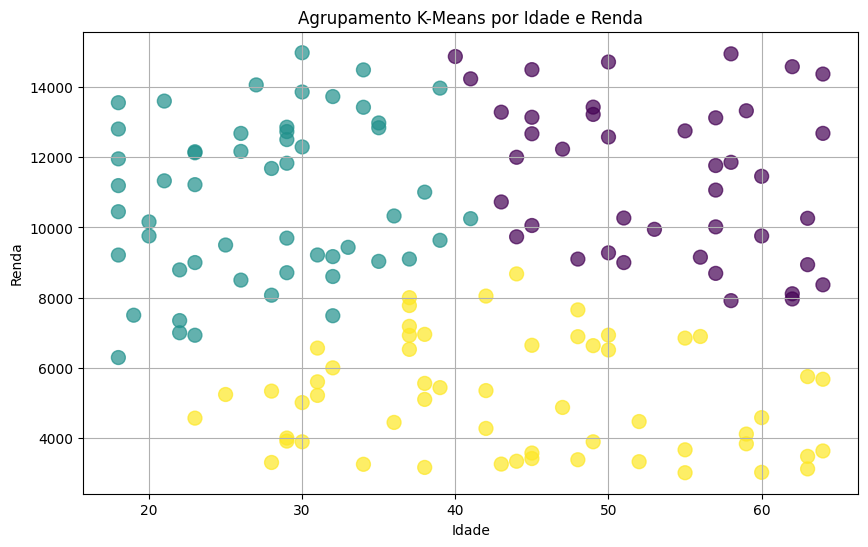

In [4]:
# Plota os clusters (usando as colunas 'Idade' e 'Renda' para visualização 2D)
plt.figure(figsize=(10, 6))
plt.scatter(df['idade'], df['renda'], c=df['Cluster_KMeans'], cmap='viridis', s=100, alpha=0.7)
plt.title('Agrupamento K-Means por Idade e Renda')
plt.xlabel('Idade')
plt.ylabel('Renda')
plt.grid(True)
plt.show()

-----

#### 4\. Agrupamento com Clusterização Hierárquica

A Clusterização Hierárquica cria uma árvore de clusters. O **dendrograma** é a representação visual dessa árvore, mostrando como os clusters se unem em diferentes níveis de similaridade.

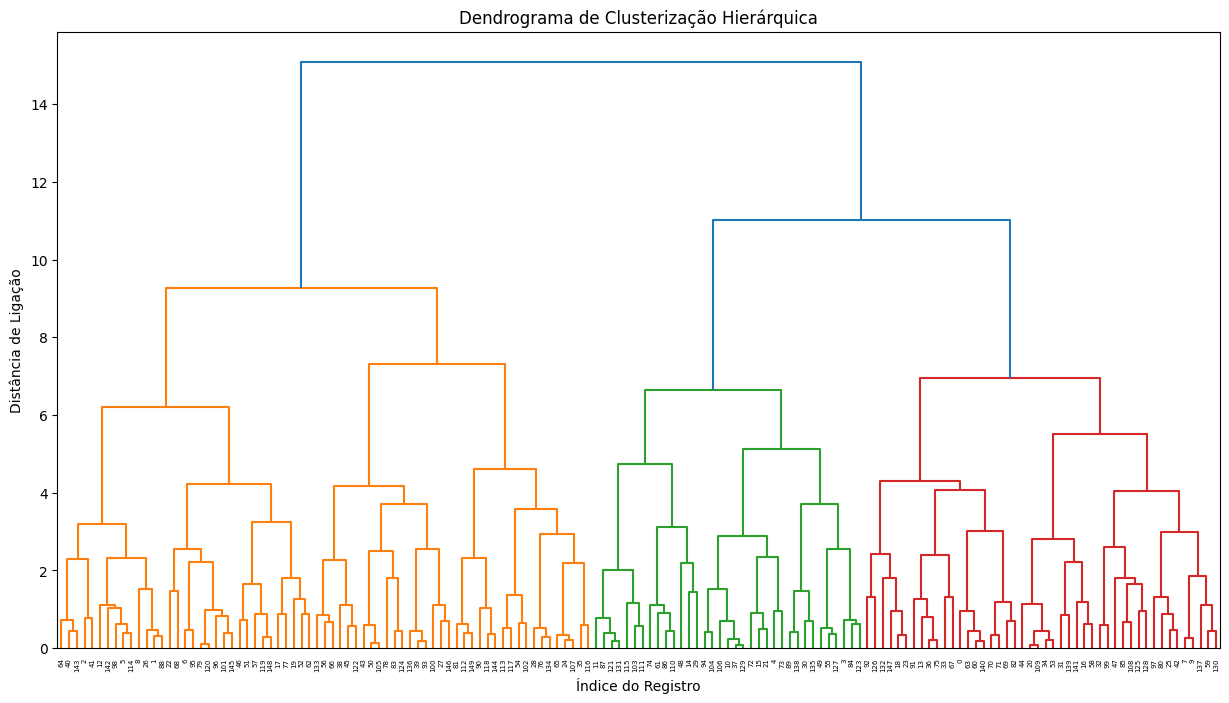


Resultados da Clusterização Hierárquica:
  emprego      estado  idade  renda credito  Cluster_KMeans  \
0     Sim    Solteiro     25   9500     Sim               1   
1     Não      Casado     37   8000     Não               2   
2     Não    Solteiro     22   7000     Não               1   
3     Sim      Casado     44  12000     Sim               0   
4     Não  Divorciado     51   9000     Sim               0   

   Cluster_Hierarquico  
0                    1  
1                    0  
2                    0  
3                    2  
4                    2  


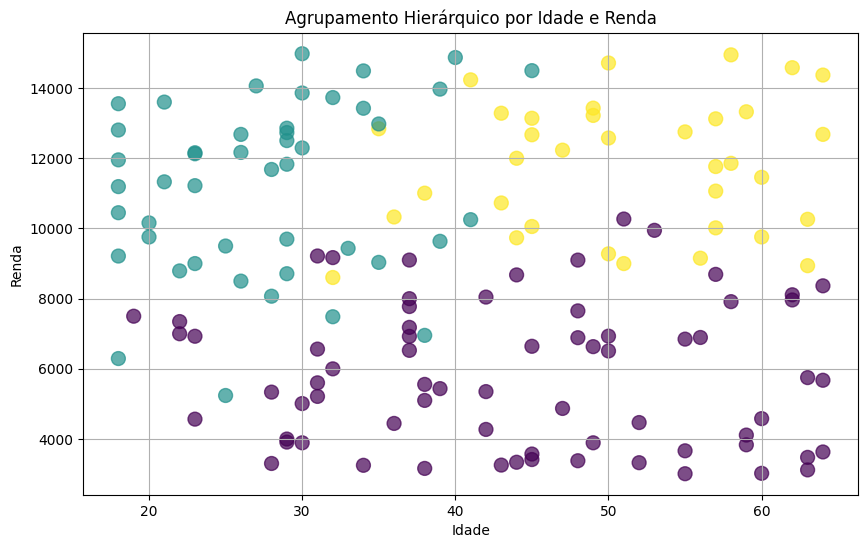

In [5]:
# Gerando a matriz de ligação para o dendrograma
Z = linkage(df_encoded, method='ward')

# Plotando o dendrograma
plt.figure(figsize=(15, 8))
dendrogram(Z, labels=df.index)
plt.title('Dendrograma de Clusterização Hierárquica')
plt.xlabel('Índice do Registro')
plt.ylabel('Distância de Ligação')
plt.show()

# Baseado no dendrograma, podemos decidir o número ideal de clusters.
# Vamos usar 3 clusters, como no K-Means, para comparação.
hierarchical_cluster = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
df['Cluster_Hierarquico'] = hierarchical_cluster.fit_predict(df_encoded)

print("\nResultados da Clusterização Hierárquica:")
print(df.head())

# Plota os clusters (usando as colunas 'Idade' e 'Renda' para visualização 2D)
plt.figure(figsize=(10, 6))
plt.scatter(df['idade'], df['renda'], c=df['Cluster_Hierarquico'], cmap='viridis', s=100, alpha=0.7)
plt.title('Agrupamento Hierárquico por Idade e Renda')
plt.xlabel('Idade')
plt.ylabel('Renda')
plt.grid(True)
plt.show()